# EduAssist AI — LLMOps Assignment 2
**Latency, token cost and prompt versioning with MLflow**

Pipeline: call an LLM → measure latency → extract tokens → compute cost → register 3 prompt versions in MLflow → evaluate with a `valid_json` metric → promote the best version to `production`.

> **Before running:** `pip install "mlflow>=3.1" openai pandas matplotlib` and set `OPENAI_API_KEY`. If the key is missing, the notebook stops with a clear message instead of making up results.

## 1. LLMOps vs MLOps (short explanation)

| Aspect | MLOps | LLMOps |
|---|---|---|
| Main artifacts | datasets, features, trained model weights | **prompts**, retrieval context, model/API version, guardrails |
| What changes | model is retrained | prompt text, model endpoint or context can each change **independently** |
| Cost driver | training + serving compute | **per-token API pricing** (input and output tokens) |
| Quality check | accuracy, F1, RMSE | JSON validity, groundedness, safety, human review; outputs are **non-deterministic** |
| Versioning | model registry | **prompt registry** + evaluation runs |

LLMOps therefore treats a prompt as a versioned production artifact, and tracks latency, token usage and cost next to quality.

In [1]:
import os, json, time, shutil, statistics
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.genai import register_prompt, load_prompt, set_prompt_alias

# ---------------- configuration ----------------
MODEL = "openai/gpt-oss-20b"            # change to any chat model you have access to
PRICE_IN_PER_1M  = 0.15          # USD per 1M input tokens  -> VERIFY on the provider pricing page
PRICE_OUT_PER_1M = 0.60          # USD per 1M output tokens -> VERIFY on the provider pricing page
MONTHLY_REQUESTS = 100_000       # assumption for the monthly projection
TEMPERATURE = 0
MAX_OUTPUT_TOKENS = 2000
RESET_MLFLOW = True              # True = start from a clean local MLflow store (avoids duplicate prompt versions on re-run)
PROMPT_NAME = "eduassist_qa_json"
EXPERIMENT  = "EduAssist-Prompt-Evaluation"

if RESET_MLFLOW:
    shutil.rmtree("mlruns", ignore_errors=True)
    if os.path.exists("mlflow.db"): os.remove("mlflow.db")

# The prompt registry needs a database-backed store, so use local SQLite
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(EXPERIMENT)
os.makedirs("outputs", exist_ok=True)
print("MLflow", mlflow.__version__)

2026/11/03 20:23:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/03 20:23:30 INFO mlflow.store.db.utils: Updating database tables


2026/11/03 20:24:02 INFO mlflow.tracking.fluent: Experiment with name 'EduAssist-Prompt-Evaluation' does not exist. Creating a new experiment.


MLflow 3.17.2


## 2. Calling the LLM, measuring latency, extracting tokens and cost

In [2]:
from openai import OpenAI
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError("Set OPENAI_API_KEY first (os.environ['OPENAI_API_KEY'] = '...'). No results are simulated.")
client = OpenAI()

def cost_usd(in_tok, out_tok):
    return in_tok / 1e6 * PRICE_IN_PER_1M + out_tok / 1e6 * PRICE_OUT_PER_1M

def call_llm(prompt_text):
    """One chat call. Returns text + latency (s) + token usage + cost."""
    t0 = time.perf_counter()
    resp = client.chat.completions.create(
        model=MODEL, temperature=TEMPERATURE, max_tokens=MAX_OUTPUT_TOKENS,
        messages=[{"role": "user", "content": prompt_text}],
    )
    latency = time.perf_counter() - t0
    u = resp.usage
    return {
        "text": resp.choices[0].message.content or "",
        "latency_s": latency,
        "input_tokens": u.prompt_tokens,
        "output_tokens": u.completion_tokens,
        "total_tokens": u.total_tokens,
        "cost_usd": cost_usd(u.prompt_tokens, u.completion_tokens),
    }

# Single-request demo
demo = call_llm("In two sentences, what is overfitting in machine learning?")
print(demo["text"])
print({k: (round(v, 6) if isinstance(v, float) else v) for k, v in demo.items() if k != "text"})

Overfitting occurs when a machine learning model captures noise and idiosyncrasies in the training data rather than the underlying pattern, resulting in excellent performance on training data but poor generalization to unseen data. It typically happens when the model is too complex relative to the amount of training data, causing it to memorize rather than learn.
{'latency_s': 0.769493, 'input_tokens': 84, 'output_tokens': 225, 'total_tokens': 309, 'cost_usd': 0.000148}


In [3]:
# Request-level and projected monthly cost for the demo call
req_cost = demo["cost_usd"]
print(f"Cost of this request : ${req_cost:.6f}")
print(f"Projected monthly    : ${req_cost * MONTHLY_REQUESTS:,.2f}  ({MONTHLY_REQUESTS:,} requests/month)")

# Repeat 5x to see latency variance (non-determinism / network effects)
lat = [call_llm("Define gradient descent in one sentence.")["latency_s"] for _ in range(5)]
print("latencies (s):", [round(x, 2) for x in lat], "| mean", round(statistics.mean(lat), 2), "| stdev", round(statistics.stdev(lat), 2))

Cost of this request : $0.000148
Projected monthly    : $14.76  (100,000 requests/month)


latencies (s): [1.69, 0.36, 0.71, 1.16, 0.71] | mean 0.93 | stdev 0.51


## 3. Three prompt versions, registered in MLflow
Prompt templates use MLflow's `{{question}}` placeholder.
- **V1** – minimal instruction (baseline)
- **V2** – explicit schema and rules
- **V3** – schema, rules and one worked example (few-shot), explicitly forbidding markdown fences

In [4]:
SCHEMA = '{"answer": "string", "confidence": "high | medium | low", "key_points": ["string"]}'

PROMPTS = {
 "V1": "Answer the academic question below and return the result as JSON.\n\nQuestion: {{question}}",

 "V2": (
  "You are an academic assistant. Answer the question and respond ONLY with a JSON object in exactly this format:\n"
  + SCHEMA + "\n"
  "Rules: 'confidence' must be one of high, medium or low. 'key_points' is a list of 2-4 short strings. "
  "Do not add any text outside the JSON.\n\nQuestion: {{question}}"),

 "V3": (
  "You are an academic assistant for university students. Respond with ONE raw JSON object and nothing else - "
  "no markdown, no code fences, no commentary.\n"
  "Format: " + SCHEMA + "\n"
  "Rules: use double quotes; 'confidence' is exactly high, medium or low; 'key_points' has 2-4 short strings; "
  "if unsure, use low confidence.\n\n"
  'Example question: What is a primary key?\n'
  'Example output: {"answer": "A primary key is a column or set of columns that uniquely identifies each row in a table.", '
  '"confidence": "high", "key_points": ["Must be unique", "Cannot be NULL", "One per table"]}\n\n'
  "Question: {{question}}"),
}

versions = {}
notes = {"V1": "Baseline: minimal instruction",
         "V2": "Explicit schema + rules",
         "V3": "Schema + rules + few-shot example + no-fence instruction"}
for tag, template in PROMPTS.items():
    p = register_prompt(name=PROMPT_NAME, template=template, commit_message=notes[tag], tags={"label": tag})
    versions[tag] = p.version
    print(tag, "-> registered as", PROMPT_NAME, "version", p.version)

V1 -> registered as eduassist_qa_json version 1


V2 -> registered as eduassist_qa_json version 2


V3 -> registered as eduassist_qa_json version 3


## 4. Test set and the `valid_json` metric
`valid_json` is strict on purpose: the raw model output must parse with `json.loads` (so a reply wrapped in ```json fences fails).
`schema_ok` is a stricter second metric: valid JSON **and** the three required keys with the right types and allowed `confidence` values.

In [5]:
QUESTIONS = [
 "What is the difference between supervised and unsupervised learning?",
 "Explain the bias-variance tradeoff.",
 "What causes inflation in an economy?",
 "Describe how photosynthesis works.",
 "What is the time complexity of binary search and why?",
 "Explain Newton's second law of motion.",
 "What is the difference between TCP and UDP?",
 "Summarise the main causes of World War I.",
 "What is a p-value in statistics?",
 "Explain what a neural network activation function does.",
]
pd.DataFrame({"question_id": range(1, len(QUESTIONS)+1), "question": QUESTIONS}).to_csv("outputs/test_questions.csv", index=False)

def valid_json(text):
    try:
        json.loads(text); return 1
    except Exception:
        return 0

def schema_ok(text):
    try:
        d = json.loads(text)
        return int(isinstance(d, dict)
                   and isinstance(d.get("answer"), str) and d["answer"].strip() != ""
                   and d.get("confidence") in ("high", "medium", "low")
                   and isinstance(d.get("key_points"), list) and len(d["key_points"]) > 0
                   and all(isinstance(k, str) for k in d["key_points"]))
    except Exception:
        return 0

# quick self-test of the metric
assert valid_json('{"a": 1}') == 1 and valid_json('```json\n{"a": 1}\n```') == 0 and valid_json("not json") == 0
assert schema_ok('{"answer":"x","confidence":"high","key_points":["a"]}') == 1
assert schema_ok('{"answer":"x","confidence":"certain","key_points":["a"]}') == 0
print("metric self-test passed")

metric self-test passed


## 5. Evaluate each prompt version (one MLflow run per version)

In [6]:
rows = []
for tag, ver in versions.items():
    prompt = load_prompt(f"prompts:/{PROMPT_NAME}/{ver}")
    with mlflow.start_run(run_name=f"{tag}_v{ver}") as run:
        mlflow.log_params({"prompt_name": PROMPT_NAME, "prompt_version": ver, "prompt_label": tag,
                           "model": MODEL, "temperature": TEMPERATURE, "n_questions": len(QUESTIONS)})
        mlflow.set_tag("mlflow.prompt.name", PROMPT_NAME)
        per_req = []
        for qi, q in enumerate(QUESTIONS, 1):
            try:
                r = call_llm(prompt.format(question=q))
            except Exception as e:
                r = {"text": f"ERROR: {e}", "latency_s": float("nan"), "input_tokens": 0,
                     "output_tokens": 0, "total_tokens": 0, "cost_usd": 0.0}
            r.update(prompt_label=tag, prompt_version=ver, question_id=qi,
                     valid_json=valid_json(r["text"]), schema_ok=schema_ok(r["text"]))
            per_req.append(r); rows.append(r)

        df = pd.DataFrame(per_req)
        metrics = {
            "valid_json_rate": df.valid_json.mean(),
            "schema_ok_rate": df.schema_ok.mean(),
            "avg_latency_s": df.latency_s.mean(),
            "p95_latency_s": df.latency_s.quantile(0.95),
            "avg_input_tokens": df.input_tokens.mean(),
            "avg_output_tokens": df.output_tokens.mean(),
            "avg_cost_usd": df.cost_usd.mean(),
            "total_cost_usd": df.cost_usd.sum(),
            "projected_monthly_cost_usd": df.cost_usd.mean() * MONTHLY_REQUESTS,
        }
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
        df.to_csv(f"outputs/results_{tag}.csv", index=False)
        mlflow.log_artifact(f"outputs/results_{tag}.csv")
        print(tag, {k: round(v, 5) for k, v in metrics.items()})

all_results = pd.DataFrame(rows)
all_results.to_csv("outputs/all_results.csv", index=False)

V1 {'valid_json_rate': np.float64(0.3), 'schema_ok_rate': np.float64(0.0), 'avg_latency_s': np.float64(0.93702), 'p95_latency_s': np.float64(1.49637), 'avg_input_tokens': np.float64(93.9), 'avg_output_tokens': np.float64(398.6), 'avg_cost_usd': np.float64(0.00025), 'total_cost_usd': np.float64(0.00253), 'projected_monthly_cost_usd': np.float64(25.3245)}


V2 {'valid_json_rate': np.float64(1.0), 'schema_ok_rate': np.float64(1.0), 'avg_latency_s': np.float64(0.85331), 'p95_latency_s': np.float64(1.52526), 'avg_input_tokens': np.float64(164.9), 'avg_output_tokens': np.float64(212.7), 'avg_cost_usd': np.float64(0.00015), 'total_cost_usd': np.float64(0.00152), 'projected_monthly_cost_usd': np.float64(15.2355)}


V3 {'valid_json_rate': np.float64(1.0), 'schema_ok_rate': np.float64(1.0), 'avg_latency_s': np.float64(2.2683), 'p95_latency_s': np.float64(4.18959), 'avg_input_tokens': np.float64(232.9), 'avg_output_tokens': np.float64(213.6), 'avg_cost_usd': np.float64(0.00016), 'total_cost_usd': np.float64(0.00163), 'projected_monthly_cost_usd': np.float64(16.3095)}


## 6. Compare versions and choose the winner
Selection rule (applied in code, in this order): highest `schema_ok_rate` → highest `valid_json_rate` → lowest `avg_cost_usd` → lowest `avg_latency_s`.
Quality gates come first because an invalid JSON reply breaks downstream parsing, which costs more than a few extra tokens.

,prompt_label,prompt_version,valid_json_rate,schema_ok_rate,avg_latency_s,p95_latency_s,avg_input_tokens,avg_output_tokens,avg_cost_usd,total_cost_usd,projected_monthly_cost_usd
0,V2,2,1.0,1.0,0.85331,1.52526,164.9,212.7,0.00015,0.00152,15.2355
1,V3,3,1.0,1.0,2.26830,4.18959,232.9,213.6,0.00016,0.00163,16.3095
2,V1,1,0.3,0.0,0.93702,1.49637,93.9,398.6,0.00025,0.00253,25.3245



Winner: V2 (registry version 2)


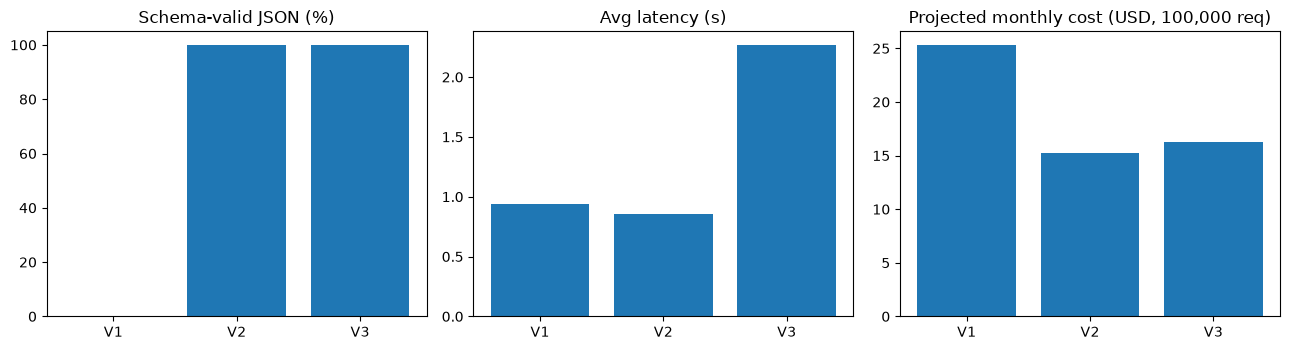

In [7]:
summary = (all_results.groupby(["prompt_label", "prompt_version"])
    .agg(valid_json_rate=("valid_json", "mean"), schema_ok_rate=("schema_ok", "mean"),
         avg_latency_s=("latency_s", "mean"), p95_latency_s=("latency_s", lambda s: s.quantile(0.95)),
         avg_input_tokens=("input_tokens", "mean"), avg_output_tokens=("output_tokens", "mean"),
         avg_cost_usd=("cost_usd", "mean"), total_cost_usd=("cost_usd", "sum"))
    .reset_index())
summary["projected_monthly_cost_usd"] = summary.avg_cost_usd * MONTHLY_REQUESTS
summary = summary.sort_values(["schema_ok_rate", "valid_json_rate", "avg_cost_usd", "avg_latency_s"],
                              ascending=[False, False, True, True]).reset_index(drop=True)
summary.to_csv("outputs/summary.csv", index=False)
display(summary.round(5))

winner = summary.iloc[0]
print(f"\nWinner: {winner.prompt_label} (registry version {winner.prompt_version})")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
s = summary.sort_values("prompt_label")
ax[0].bar(s.prompt_label, s.schema_ok_rate*100); ax[0].set_title("Schema-valid JSON (%)"); ax[0].set_ylim(0, 105)
ax[1].bar(s.prompt_label, s.avg_latency_s);       ax[1].set_title("Avg latency (s)")
ax[2].bar(s.prompt_label, s.projected_monthly_cost_usd); ax[2].set_title(f"Projected monthly cost (USD, {MONTHLY_REQUESTS:,} req)")
plt.tight_layout(); plt.savefig("outputs/comparison.png", dpi=150); plt.show()

## 7. Promote the best version to production
The `production` alias points at the winning version. Applications load `prompts:/eduassist_qa_json@production`, so promotion/rollback needs no code change.

In [8]:
set_prompt_alias(PROMPT_NAME, alias="production", version=int(winner.prompt_version))
prod = load_prompt(f"prompts:/{PROMPT_NAME}@production")
print("production alias -> version", prod.version)
print(prod.template)

# End-to-end check using the production prompt
chk = call_llm(prod.format(question="What is regularisation in machine learning?"))
print(chk["text"]); print("valid_json:", valid_json(chk["text"]), "| schema_ok:", schema_ok(chk["text"]))

production alias -> version 2
You are an academic assistant. Answer the question and respond ONLY with a JSON object in exactly this format:
{"answer": "string", "confidence": "high | medium | low", "key_points": ["string"]}
Rules: 'confidence' must be one of high, medium or low. 'key_points' is a list of 2-4 short strings. Do not add any text outside the JSON.

Question: {{question}}


{"answer":"Regularisation is a set of techniques used in machine learning to prevent overfitting by adding a penalty term to the loss function that discourages overly complex models. It encourages simpler models that generalise better to unseen data.","confidence":"high","key_points":["Prevents overfitting","Adds penalty (L1/L2)","Controls model complexity","Improves generalisation"]}
valid_json: 1 | schema_ok: 1


## 8. Auto-generate the short report (500-700 words) from the real numbers

In [9]:
def generate_report(summary, winner, model, monthly_requests, n_q):
    s = summary.sort_values("prompt_label").set_index("prompt_label")
    cheapest = s.avg_cost_usd.idxmin(); fastest = s.avg_latency_s.idxmin()
    rows_md = "\n".join(
        f"| {k} | {r.valid_json_rate*100:.0f}% | {r.schema_ok_rate*100:.0f}% | {r.avg_latency_s:.2f} | "
        f"{r.avg_input_tokens:.0f} / {r.avg_output_tokens:.0f} | ${r.avg_cost_usd:.6f} | ${r.projected_monthly_cost_usd:,.2f} |"
        for k, r in s.iterrows())
    w = winner.prompt_label
    return f'''# EduAssist AI - LLMOps Report: Prompt Versioning, Latency and Cost

## 1. LLMOps and how it differs from MLOps
MLOps manages datasets, feature pipelines, training and deployment of models. LLMOps manages the whole LLM application lifecycle, where prompts, retrieved context, the model or API version and output guardrails can each change independently and each affects quality. Cost also shifts from training compute to per-token API charges, and outputs are non-deterministic, so automated checks such as JSON validity replace simple accuracy metrics. For this reason prompts are treated as versioned production artifacts.

## 2. Method
I built an academic question-answering assistant that must return strict JSON with the keys answer, confidence (high, medium or low) and key_points. Using {model} at temperature 0, I measured latency with a wall-clock timer around each API call and read input, output and total tokens from the response usage field. Cost per request is input tokens times the input price plus output tokens times the output price; the monthly projection multiplies the average request cost by an assumed {monthly_requests:,} requests per month. Three prompts were registered as versions 1 to 3 of one MLflow prompt: V1 is a minimal instruction, V2 adds the explicit schema and rules, and V3 adds a worked example and forbids markdown fences. Each version answered the same {n_q} questions in its own MLflow run. The valid_json metric requires the raw reply to parse with json.loads; schema_ok additionally checks keys, types and allowed confidence values.

## 3. Results
| Version | valid_json | schema_ok | Avg latency (s) | Avg tokens in / out | Avg cost per request | Projected monthly cost |
|---|---|---|---|---|---|---|
{rows_md}

{w} achieved the best quality ranking ({s.loc[w].schema_ok_rate*100:.0f}% schema-valid, {s.loc[w].valid_json_rate*100:.0f}% valid JSON). The cheapest version was {cheapest} and the fastest was {fastest}. Longer prompts raise input tokens and therefore cost, while longer answers raise output tokens and latency, so the cheapest or fastest prompt is not automatically the best one.

## 4. Decision and promotion
Versions were ranked by schema_ok, then valid_json, then cost, then latency, because a malformed reply breaks downstream parsing and costs more than a few extra tokens. {w} (registry version {int(winner.prompt_version)}) ranked first and was promoted by pointing the production alias at it. Applications load the prompt through the production alias, so a promotion or rollback is one alias change with no code deployment, and every evaluation run stays linked to the exact prompt version it tested.

## 5. Limitations and next steps
The test set has only {n_q} questions, so differences of one or two replies are not statistically strong, and latency depends on network conditions and provider load. Prices and the monthly volume are assumptions that should be checked against current provider pricing and real traffic. Next steps are a larger and more diverse evaluation set, repeated runs to measure variance, a semantic quality score such as LLM-as-judge or human review of answer correctness, and safety checks before any further promotion.
'''

report = generate_report(summary, winner, MODEL, MONTHLY_REQUESTS, len(QUESTIONS))
open("outputs/report.md", "w").write(report)
words = len(report.split())
print("report words:", words, "(target 500-700; table cells count)")

report words: 541 (target 500-700; table cells count)


## 9. Screenshots and export
1. Run `mlflow ui --backend-store-uri sqlite:///mlflow.db` in this folder and open http://127.0.0.1:5000.
2. Take screenshots of: **Prompts** tab (3 versions + `production` alias), **Experiments → EduAssist-Prompt-Evaluation** (3 runs), and the **compare runs** view (select all 3 runs → Compare).
3. Export: `jupyter nbconvert --to html LLMOps_Assignment2.ipynb` (and `--to pdf`, or print the HTML to PDF).
4. Submit: notebook, HTML/PDF, `outputs/*.csv`, screenshots, `outputs/report.md`.